In [ ]:
import requests
from pathlib import Path

import osmnx as ox
import geopandas as gpd
import pandas as pd
import shapely

import matplotlib.pyplot as plt
from matplotlib import patheffects as pe
from matplotlib.lines import Line2D

# folders
EXTERNAL_PATH = Path("../data/processed")
EXTERNAL_PATH.mkdir(exist_ok=True)
PROCESSED_PATH = Path("../data/processed")
PROCESSED_PATH.mkdir(exist_ok=True)
OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)

# variables
CRS_PLOT = "EPSG:31287"

In [ ]:
url = "https://download.geofabrik.de/europe/austria-latest.osm.pbf"
pbf_path = EXTERNAL_PATH / "austria-latest.osm.pbf"


if not pbf_path.exists():
    with requests.get(url, stream=True, timeout=60) as r: 
        r.raise_for_status() 
        with open(pbf_path, "wb") as f: 
            for chunk in r.iter_content(chunk_size=1024 * 1024): 
                f.write(chunk)
else:
    with open(pbf_path, "rb") as f:
        for chunk in f:
            pass  # just read the file to ensure it's accessible

print(f"{pbf_path.stat().st_size / 1e6:.0f} MB")

814 MB


In [12]:
austria_path = PROCESSED_PATH / "austria_boundary.gpkg"

if austria_path.exists():
    # read the boundary of Austria from a GeoPackage file if it exists
    austria = gpd.read_file(austria_path)
    austria_geom = austria.union_all()
    print(shapely.get_num_coordinates(austria_geom), "vértices en el límite")
else:
    # otherwise, download the boundary of Austria from OSM and save it to a GeoPackage file
    austria = ox.geocode_to_gdf("Austria").to_crs(CRS_PLOT)
    austria.to_file(austria_path, driver="GPKG")
    austria_geom = austria.union_all()
    print(shapely.get_num_coordinates(austria_geom), "vértices en el límite")

126993 vértices en el límite


In [13]:
rail_path = PROCESSED_PATH / "austria_rail.gpkg"

if rail_path.exists():
    rail = gpd.read_file(rail_path)
    print(f"Cargado desde disco: {len(rail):,} segmentos")
else:
    # aquí va la lectura del .pbf y el procesamiento
    rail = gpd.read_file(
        pbf_path,
        engine="pyogrio",
        sql="SELECT * FROM lines WHERE railway = 'rail'",
        sql_dialect="OGRSQL",
    )
    print(len(rail), "líneas leídas")

    def tag(series, key):
        """Extrae un valor de other_tags (formato hstore de GDAL)."""
        return series.str.extract(rf'"{key}"=>"([^"]*)"')[0]

    rail["electrified"] = tag(rail["other_tags"], "electrified")
    rail["service"]     = tag(rail["other_tags"], "service")
    rail["usage"]       = tag(rail["other_tags"], "usage")

    # Excluir vías de servicio (apartaderos, playas de vías...)
    rail = rail[rail["service"].isna()].copy()

    rail["is_electrified"] = rail["electrified"].notna() & (rail["electrified"] != "no")
    rail = rail[["name", "usage", "electrified", "is_electrified", "geometry"]].to_crs(CRS_PLOT)

    print(rail["is_electrified"].value_counts())
    print(rail["usage"].value_counts(dropna=False).head())
    rail.to_file(rail_path, driver="GPKG")

53679 líneas leídas
is_electrified
True     24679
False     5238
Name: count, dtype: int64
usage
main          23085
branch         6160
industrial      356
tourism         206
NaN             102
Name: count, dtype: int64


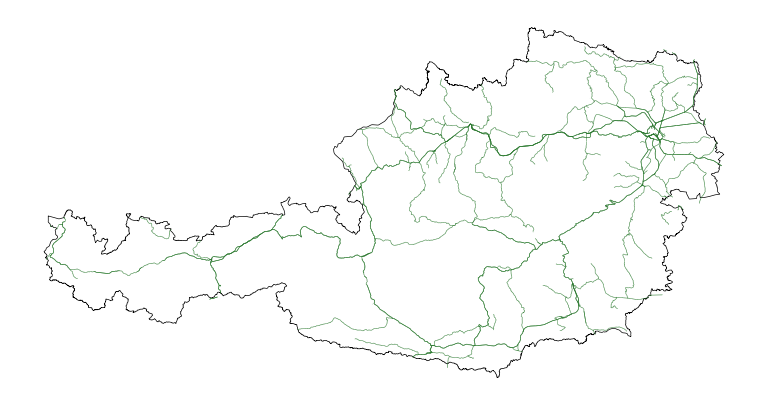

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
austria.boundary.plot(ax=ax, color="black", linewidth=0.5)
rail.plot(ax=ax, color="#2e7d32", linewidth=0.4)
ax.set_axis_off()
plt.show()

In [15]:
print(rail.crs)                          # debe ser EPSG:31287
print(rail.geometry.is_valid.all())      # geometrías válidas
print(rail.geometry.is_empty.sum())      # debe ser 0
print(rail.geom_type.value_counts(), "\n")     # solo LineString / MultiLineString

# Cuánto de la información viene realmente etiquetada
print(rail["electrified"].value_counts(dropna=False), "\n")
print(rail["usage"].value_counts(dropna=False))

EPSG:31287
True
0
LineString    29917
Name: count, dtype: int64 

electrified
contact_line    24679
no               5226
NaN                12
Name: count, dtype: int64 

usage
main          23085
branch         6160
industrial      356
tourism         206
NaN             102
military          6
test              2
Name: count, dtype: int64


In [16]:
rail_map = rail[rail["usage"].isin(["main", "branch"])].copy()
print(f"{len(rail_map):,} segmentos tras filtrar por usage")

29,245 segmentos tras filtrar por usage


In [17]:
shapely.prepare(austria_geom)   # acelera las comprobaciones espaciales repetidas

inside = rail_map.within(austria_geom)
inner = rail_map[inside]
border = gpd.clip(rail_map[~inside], austria_geom)
border = border[border.geom_type.isin(["LineString", "MultiLineString"])]
rail_map = pd.concat([inner, border], ignore_index=True)
rail_map["length_km"] = rail_map.geometry.length / 1000

total = rail_map["length_km"].sum()
print(f"Total: {total:,.0f} km\n")
print((rail_map.groupby("is_electrified")["length_km"].sum() / total).round(3))

rail_map = rail_map[rail_map.geom_type.isin(["LineString", "MultiLineString"])].copy()
print(rail_map.geom_type.value_counts())

Total: 7,912 km

is_electrified
False    0.174
True     0.826
Name: length_km, dtype: float64
LineString         29136
MultiLineString        2
Name: count, dtype: int64


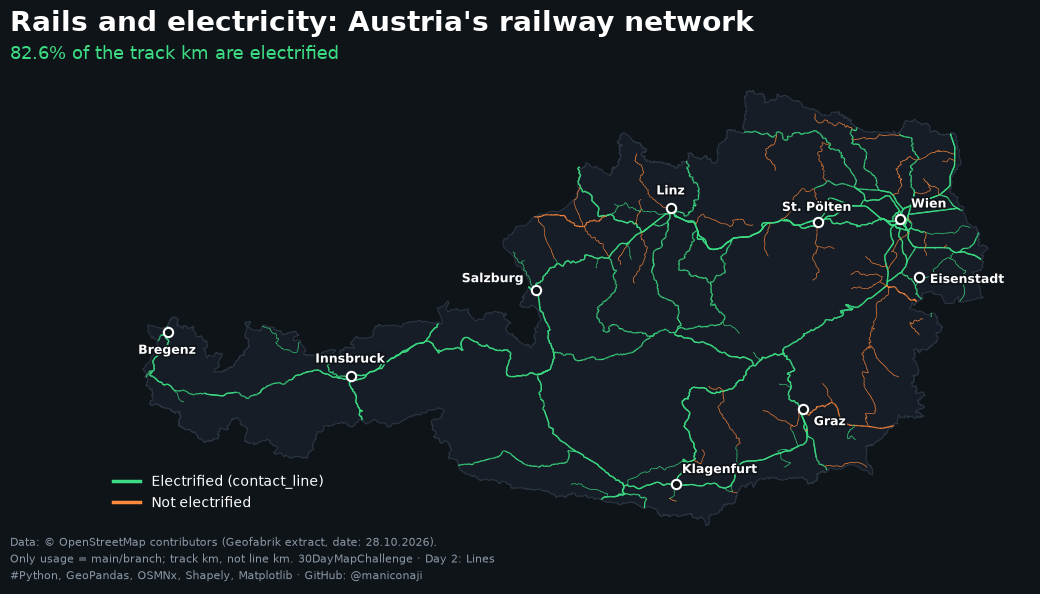

In [ ]:
# BG = "#0f1419"
# GREEN = "#3ddc84"
# ORANGE = "#ff8a3d"
# GREY = "#2a3440"

# # nombre: (lon, lat, desplazamiento_x, desplazamiento_y, alineación)
# capitals = {
#     "Wien":             (16.3738, 48.2082,  8,  8, "left"),
#     "St. Pölten":       (15.6256, 48.2047,  0, 8, "center"),
#     "Eisenstadt":       (16.5233, 47.8456,  8, -4, "left"),
#     "Linz":             (14.2858, 48.3069,  0, 10, "center"),
#     "Salzburg":         (13.0550, 47.8095, -8,  6, "right"),
#     "Innsbruck":        (11.4041, 47.2692,  0, 10, "center"),
#     "Bregenz":          ( 9.7471, 47.5031,  0, -16, "center"),
#     "Klagenfurt":       (14.3050, 46.6247,  4, 8, "left"),
#     "Graz":             (15.4395, 47.0707,  8, -12, "left"),
# }

# cap = gpd.GeoDataFrame(
#     {"name": list(capitals.keys())},
#     geometry=gpd.points_from_xy(
#         [v[0] for v in capitals.values()],
#         [v[1] for v in capitals.values()],
#     ),
#     crs="EPSG:4326",
# ).to_crs(CRS_PLOT)


# fig, ax = plt.subplots(figsize=(12, 7), facecolor=BG)
# ax.set_facecolor(BG)

# # Silueta del país
# austria.plot(
#     ax=ax, 
#     color="#161d26", 
#     edgecolor=GREY, 
#     linewidth=0.8)

# # Capas: primero lo no electrificado, luego lo electrificado encima
# for is_el, color in [(False, ORANGE), (True, GREEN)]:
#     for usage, lw in [("branch", 0.5), ("main", 0.9)]:
#         sub = rail_map[(rail_map["is_electrified"] == is_el) & (rail_map["usage"] == usage)]
#         sub.plot(
#             ax=ax, 
#             color=color, 
#             linewidth=lw, 
#             zorder=3 if is_el else 4)

# ax.set_axis_off()

# # Título
# fig.text(
#     0.05, 0.89, 
#     "Rails and electricity: Austria's railway network",
#     color="white", 
#     fontsize=20, 
#     fontweight="bold", 
#     ha="left")
# fig.text(
#     0.05, 0.85,
#     f"{rail_map.loc[rail_map.is_electrified, 'length_km'].sum() / total:.1%} of the track km are electrified",
#     color=GREEN, 
#     fontsize=13, 
#     ha="left")

# # Leyenda manual
# handles = [
#     Line2D([0], [0], color=GREEN, lw=2.5, label="Electrified (contact_line)"),
#     Line2D([0], [0], color=ORANGE, lw=2.5, label="Not electrified")]

# ax.legend(
#     handles=handles, 
#     loc="lower left", 
#     frameon=False,
#     labelcolor="white", 
#     fontsize=10, 
#     bbox_to_anchor=(0.0, 0.05))

# # Pie
# fig.text(
#     0.05, 0.1,
#     "Data: © OpenStreetMap contributors (Geofabrik extract, date: 28.10.2026).\n"
#     "Only usage = main/branch; track km, not line km. 30DayMapChallenge · Day 2: Lines\n"
#     "#Python, GeoPandas, OSMNx, Shapely, Matplotlib · GitHub: @maniconaji", 
#     color="#8b98a5", 
#     fontsize=8, 
#     ha="left", 
#     va="bottom",
#     linespacing=1.5) #Mapa ilustrativo: la alineación con la Taxonomía UE (act. 6.1/6.2) depende de criterios técnicos y DNSH. 

# # Marcador distinto al de la red (anillo blanco hueco), para no confundirlo con otros puntos
# cap.plot(ax=ax, facecolor=BG, edgecolor="white", markersize=45, linewidth=1.5, zorder=6)

# halo = [pe.withStroke(linewidth=2.5, foreground=BG)]  # contorno oscuro para legibilidad
# for _, row in cap.iterrows():
#     dx, dy, ha = capitals[row["name"]][2:]
#     ax.annotate(
#         row["name"],
#         xy=(row.geometry.x, row.geometry.y),
#         xytext=(dx, dy), 
#         textcoords="offset points",
#         color="white", 
#         fontsize=9, 
#         fontweight="bold",
#         ha=ha, 
#         zorder=7, 
#         path_effects=halo)

# handles.append(
#     Line2D(
#         [0], [0], 
#         marker="o", 
#         color="none", 
#         markerfacecolor=BG,
#         markeredgecolor="white", 
#         markersize=7, 
#         label="Capital de Bundesland"))


# plt.savefig(OUT / "day02_lines_rail.png", dpi=300, facecolor=BG, bbox_inches="tight")
# plt.show()

Bregenz
Innsbruck
Salzburg
Linz
Klagenfurt
Graz
St. Pölten
Wien
Eisenstadt


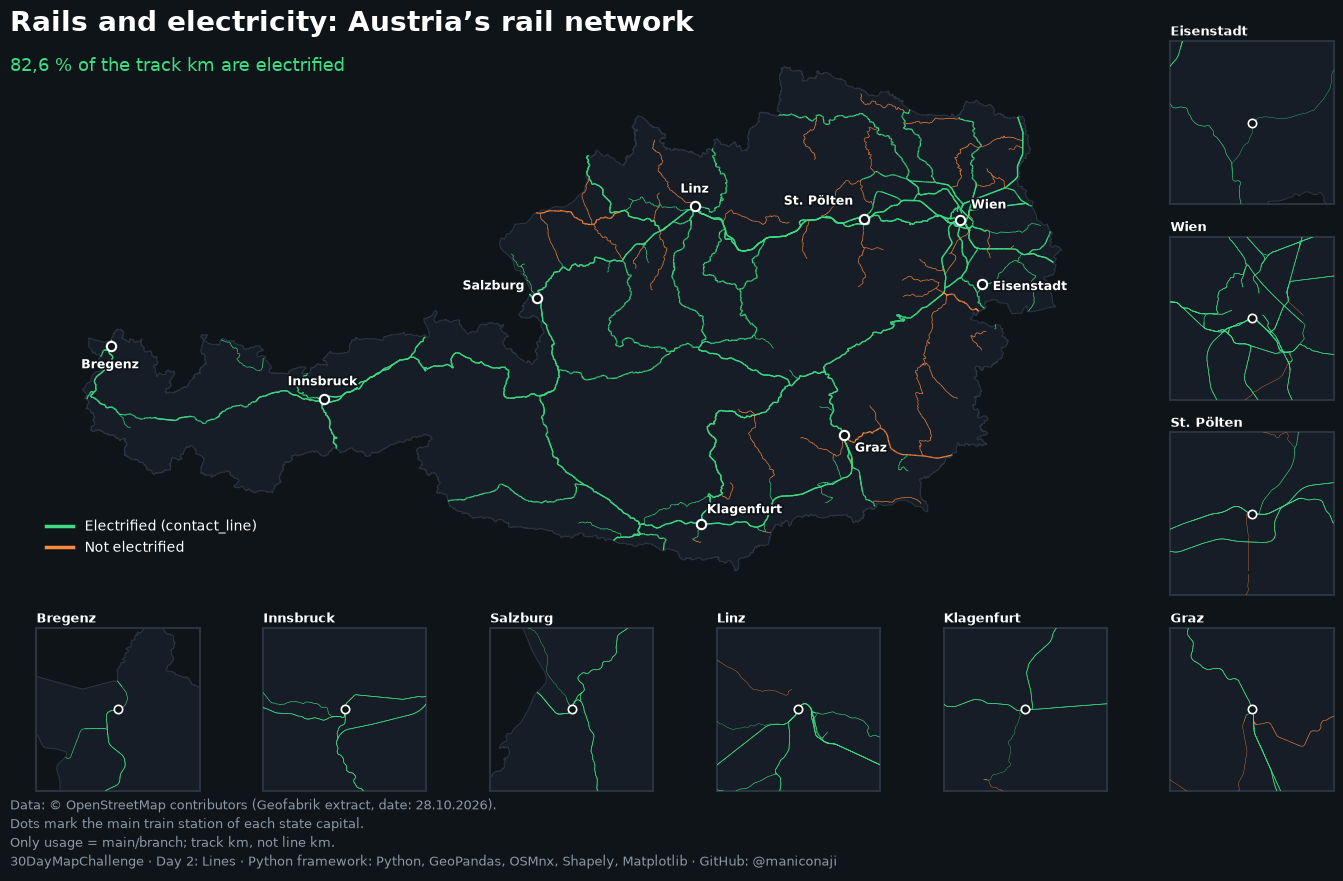

In [101]:
BG = "#0f1419"
GREEN = "#3ddc84"
ORANGE = "#ff8a3d"
GREY = "#2a3440"

# nombre: (lon, lat, desplazamiento_x, desplazamiento_y, alineación)
capitals = {
    "Wien":        (16.3764, 48.1853,  8,  8, "left"),    # Wien Hauptbahnhof @48.1851908,16.3740224
    "St. Pölten":  (15.6231, 48.2083, -6, 10, "right"),   # St. Pölten Hbf @48.2079336,15.6220991
    "Eisenstadt":  (16.5263, 47.8393,  8, -4, "left"),    # Eisenstadt Hbf 47.8392507,16.5263252
    "Linz":        (14.2916, 48.2903,  0, 10, "center"),  # Linz Hbf @48.2903035,14.2890251
    "Salzburg":    (13.0458, 47.8130, -8,  6, "right"),   # Salzburg Hbf @47.8130308,13.0424637
    "Innsbruck":   (11.4010, 47.2633,  0, 10, "center"),  # Innsbruck Hbf @47.2635851,11.3981777
    "Bregenz":     ( 9.7395, 47.5028,  0, -16, "center"), # Bregenz Bahnhof @47.5027755,9.7395371
    "Klagenfurt":  (14.3105, 46.6163,  4, 8, "left"),     # Klagenfurt Hbf @46.6162661,14.310482
    "Graz":        (15.4170, 47.0723,  8, -12, "left"),   # Graz Hbf @47.0729738,15.4147428
}

cap = gpd.GeoDataFrame(
    {"name": list(capitals.keys())},
    geometry=gpd.points_from_xy(
        [v[0] for v in capitals.values()],
        [v[1] for v in capitals.values()],
    ),
    crs="EPSG:4326",
).to_crs(CRS_PLOT)

fig = plt.figure(figsize=(15, 10), facecolor=BG, )

# subplot2grid((nrows, ncols), (row, col), rowspan, colspan)
ax1 = plt.subplot2grid((4, 6), (0, 0), rowspan=3, colspan=5)
ax2 = plt.subplot2grid((4, 6), (3, 0), rowspan=1, colspan=1)
ax3 = plt.subplot2grid((4, 6), (3, 1), rowspan=1, colspan=1)
ax4 = plt.subplot2grid((4, 6), (3, 2), rowspan=1, colspan=1)
ax5 = plt.subplot2grid((4, 6), (3, 3), rowspan=1, colspan=1)
ax6 = plt.subplot2grid((4, 6), (3, 4), rowspan=1, colspan=1)
ax7 = plt.subplot2grid((4, 6), (3, 5), rowspan=1, colspan=1)
ax8 = plt.subplot2grid((4, 6), (2, 5), rowspan=1, colspan=1)
ax9 = plt.subplot2grid((4, 6), (1, 5), rowspan=1, colspan=1)
ax10 = plt.subplot2grid((4, 6), (0, 5), rowspan=1, colspan=1)

# mapa principal
ax = ax1
ax.set_facecolor(BG)
ax.set_axis_off()

## Silueta del país
austria.plot(
    ax=ax, 
    color="#161d26", 
    edgecolor=GREY, 
    linewidth=0.8)

## Capas: primero lo no electrificado, luego lo electrificado encima
for is_el, color in [(False, ORANGE), (True, GREEN)]:
    for usage, lw in [("branch", 0.5), ("main", 0.9)]:
        sub = rail_map[(rail_map["is_electrified"] == is_el) & (rail_map["usage"] == usage)]
        sub.plot(
            ax=ax, 
            color=color, 
            linewidth=lw, 
            zorder=3 if is_el else 4)

## Leyenda manual del mapa grande
handles = [
    Line2D([0], [0], color=GREEN, lw=2.5, label="Electrified (contact_line)"),
    Line2D([0], [0], color=ORANGE, lw=2.5, label="Not electrified")]

ax.legend(
    handles=handles, 
    loc="lower left", 
    frameon=False,
    labelcolor="white", 
    fontsize=10, 
    bbox_to_anchor=(0.0, 0.05))

## Marcador distinto al de la red (anillo blanco hueco), para no confundirlo con otros puntos
cap.plot(ax=ax, facecolor=BG, edgecolor="white", markersize=45, linewidth=1.5, zorder=6)

halo = [pe.withStroke(linewidth=2.5, foreground=BG)]  # contorno oscuro para legibilidad
for _, row in cap.iterrows():
    dx, dy, ha = capitals[row["name"]][2:]
    ax.annotate(
        row["name"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(dx, dy), 
        textcoords="offset points",
        color="white", 
        fontsize=9, 
        fontweight="bold",
        ha=ha, 
        zorder=7, 
        path_effects=halo)

handles.append(
    Line2D(
        [0], [0], 
        marker="o", 
        color="none", 
        markerfacecolor=BG,
        markeredgecolor="white", 
        markersize=7, 
        label="Capital de Bundesland"))

# Minimaps

## valores por defecto, en km
RADIUS_KM = 10                       # medio lado del recuadro
RADIUS_OVERRIDE = {"Wien": 12}       # ciudades que piden más contexto
ORDER = ["Bregenz", "Innsbruck", "Salzburg", "Linz", "Klagenfurt", "Graz", "St. Pölten", "Wien", "Eisenstadt"]   # oeste → este, en filas

# Función auxiliar para dibujar la red ferroviaria en un eje dado
def draw_rail(ax, data, scale=1.0):
    for is_el, color in [(False, ORANGE), (True, GREEN)]:
        for usage, lw in [("branch", 0.5), ("main", 0.9)]:
            sub = data[(data["is_electrified"] == is_el) & (data["usage"] == usage)]
            if len(sub):
                sub.plot(
                    ax=ax, color=color, linewidth=lw * scale, zorder=3 if is_el else 4)

# Dibujar minimaps
for i, (name, ax) in enumerate(zip(ORDER, [ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9, ax10])):
    print(name)
    pt = cap.loc[cap["name"] == name, "geometry"].iloc[0]
    r = RADIUS_OVERRIDE.get(name, RADIUS_KM) * 1000
    xmin, xmax, ymin, ymax = pt.x - r, pt.x + r, pt.y - r, pt.y + r

    austria.plot(
    ax=ax, 
    color="#161d26", 
    edgecolor=GREY, 
    linewidth=0.8)

    local = rail_map.cx[xmin:xmax, ymin:ymax]
    draw_rail(ax, local, scale=0.5)

    ax.plot(pt.x, pt.y, "o", mfc=BG, mec="white", mew=1.2, ms=6, zorder=6)
    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color(GREY); s.set_linewidth(1.5)
    ax.set_xlabel(""); ax.set_ylabel(""); ax.set_facecolor(BG)

    # Título del recuadro + % electrificado en ese recuadro
    tot = local["length_km"].sum()
    pct = local.loc[local["is_electrified"], "length_km"].sum() / tot if tot else float("nan")
    ax.set_title(f"{name}", color="white", fontsize=9, fontweight="bold", loc="left", pad=4)


# Texto de título y subtítulo
## Título
fig.text(
    0.05, 0.89, 
    "Rails and electricity: Austria’s rail network",
    color="white", 
    fontsize=20, 
    fontweight="bold", 
    ha="left")

## Subtítulo
pct = rail_map.loc[rail_map["is_electrified"], "length_km"].sum() / total
fig.text(
    0.05, 0.85,
    f"{pct * 100:.1f} %".replace(".", ",") + " of the track km are electrified",
    color=GREEN, 
    fontsize=13, 
    ha="left")

## Pie de pagina con créditos y licencia de datos
fig.text(
    0.05, 0.05,
    "Data: © OpenStreetMap contributors (Geofabrik extract, date: 28.10.2026).\n"
    "Dots mark the main train station of each state capital.\n"
    "Only usage = main/branch; track km, not line km.\n"
    "30DayMapChallenge · Day 2: Lines · Python framework: Python, GeoPandas, OSMnx, Shapely, Matplotlib · GitHub: @maniconaji",
    color="#8b98a5", 
    fontsize=9, 
    ha="left", 
    va="bottom",
    linespacing=1.5) #Mapa ilustrativo: la alineación con la Taxonomía UE (act. 6.1/6.2) depende de criterios técnicos y DNSH. 

fig.subplots_adjust(left=0.05, right=0.95, top=0.88, bottom=0.13, wspace=0.05, hspace=0.2)

plt.savefig(OUT / "day02_lines_rail.png", dpi=300, facecolor=BG, bbox_inches="tight")
plt.show()